In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv('/content/fairfare_ride_demand_dataset.csv')

In [ ]:
df

,City,Date,Day_of_Week,Latitude,Longitude,Ride_Distance_KM,Ride_Type,Weather,Event,Payment_Type,...,Fare_Acceptance,Cancellation_Rate,Time_of_Day,Demand_Score,Driver_Availability,Traffic_Delay,Cancellation_Probability,Driver_Trust_Score,Rider_Trust_Score,Leaderboard_Rank
0,Hyderabad,06-08-2024,1,17.353253,78.466332,6.76,Economy,Cloudy,Festival,UPI,...,0.857885,0.07,Afternoon,80,46,15,0.2,100.0,100,Below Average
1,Mumbai,26-09-2024,3,19.059839,72.858877,3.34,Premium,Stormy,Political Rally,Card,...,0.747193,0.07,Morning Peak,100,86,25,0.3,100.0,50,Below Average
2,Bangalore,27-07-2024,5,12.976855,77.625306,8.86,Luxury,Rainy,Festival,UPI,...,0.868523,0.08,Afternoon,100,32,15,0.3,100.0,100,Below Average
3,Mumbai,23-03-2025,6,19.056439,72.863508,15.95,Luxury,Cloudy,Concert,Cash,...,0.859991,0.07,Evening Peak,95,95,25,0.1,100.0,100,Below Average
4,Chennai,06-08-2024,1,13.110869,80.309381,19.50,Premium,Clear,NaN,Card,...,0.981357,0.05,Evening Peak,65,58,10,0.1,0.0,0,Below Average
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,Chennai,27-11-2024,2,13.055881,80.273332,7.90,Economy,Stormy,Concert,UPI,...,0.837925,0.01,Morning Peak,100,30,25,0.3,100.0,100,Below Average
9996,Mumbai,03-12-2024,1,19.110041,72.924592,19.27,Premium,Rainy,Political Rally,Cash,...,0.703415,0.03,Afternoon,100,64,15,0.3,100.0,25,Below Average
9997,Hyderabad,16-10-2024,2,17.365359,78.437935,11.97,Economy,Rainy,NaN,Card,...,0.854021,0.10,Morning Peak,85,81,10,0.3,100.0,100,Below Average
9998,Hyderabad,17-03-2025,0,17.355769,78.531133,11.44,Luxury,Rainy,Concert,Card,...,0.998016,0.07,Morning Peak,100,82,25,0.3,100.0,100,Below Average


In [ ]:
X = df[['City','Day_of_Week','Ride_Distance_KM','Ride_Type','Weather','Event','Payment_Type'
,'Available_Drivers','Demand_Level','Surge_Multiplier','Hour_of_Day','Is_Weekend','Time_of_Day',
'Demand_Score','Driver_Availability','Traffic_Delay','Ride_Priority']]

In [ ]:
y = df['Final_Fare']

In [ ]:
import sklearn
from sklearn.model_selection import train_test_split

In [ ]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import time

In [ ]:
categorical_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()
numerical_cols = X_train.select_dtypes(include=["int64", "float64", "int32", "float32", "bool"]).columns.tolist()

print("Categorical columns:", categorical_cols)
print("Numerical columns:", numerical_cols)

Categorical columns: ['City', 'Ride_Type', 'Weather', 'Event', 'Payment_Type', 'Time_of_Day']
Numerical columns: ['Day_of_Week', 'Ride_Distance_KM', 'Available_Drivers', 'Demand_Level', 'Surge_Multiplier', 'Hour_of_Day', 'Is_Weekend', 'Demand_Score', 'Driver_Availability', 'Traffic_Delay', 'Ride_Priority']


In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("num", StandardScaler(), numerical_cols)
    ]
)

In [ ]:
models = {
    "Linear Regression": LinearRegression(),

    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=200,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost Regressor": XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )
}

In [ ]:
results = []
trained_models = {}

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    start_time = time.time()

    pipeline.fit(X_train, y_train)

    train_time = time.time() - start_time

    y_pred = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2,
        "Training Time (s)": round(train_time, 2)
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results)

results_df.sort_values(by="R2 Score", ascending=False)

,Model,MAE,RMSE,R2 Score,Training Time (s)
2,XGBoost Regressor,2.345634,3.851950,0.998393,0.83
1,Random Forest Regressor,2.560370,4.572395,0.997736,24.47
0,Linear Regression,15.471232,22.414083,0.945589,0.08


In [ ]:
import joblib

best_model = trained_models["XGBoost Regressor"]

joblib.dump(best_model, "ride_fare_xgboost_model.pkl")

['ride_fare_xgboost_model.pkl']

In [ ]:
results_df.to_csv("model_comparison_results.csv", index=False)

In [ ]:
best_model = trained_models["XGBoost Regressor"]

preprocessor = best_model.named_steps["preprocessor"]
xgb_model = best_model.named_steps["model"]

feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_model.feature_importances_
})

importance_df = importance_df.sort_values(by="Importance", ascending=False)

importance_df.head(15)

,Feature,Importance
25,num__Ride_Distance_KM,0.515790
28,num__Surge_Multiplier,0.164095
3,cat__City_Hyderabad,0.065104
0,cat__City_Bangalore,0.056311
4,cat__City_Mumbai,0.041489
26,num__Available_Drivers,0.037414
2,cat__City_Delhi,0.024428
27,num__Demand_Level,0.018943
1,cat__City_Chennai,0.017696
19,cat__Payment_Type_UPI,0.007201


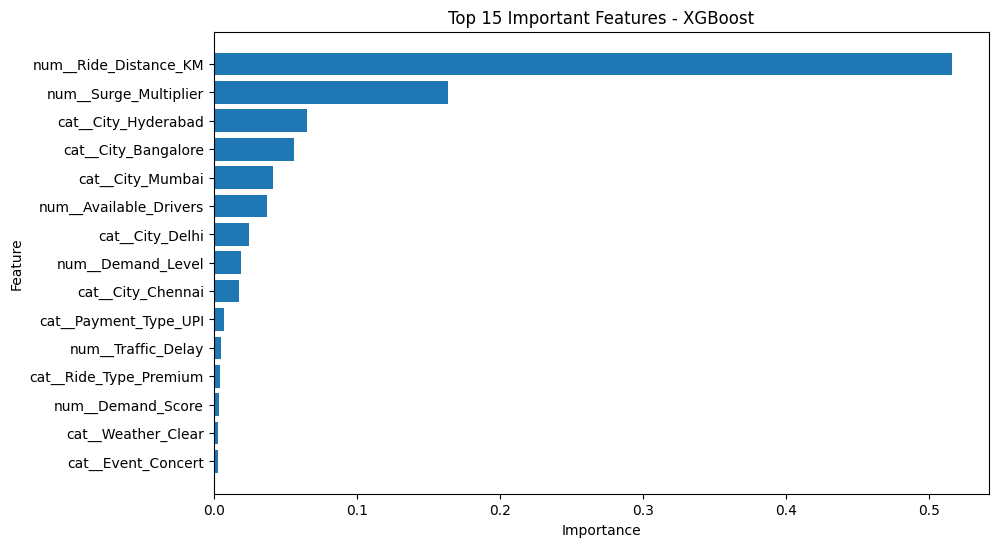

In [ ]:
import matplotlib.pyplot as plt

top_features = importance_df.head(15)

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Important Features - XGBoost")
plt.show()

In [ ]:
from google.colab import files

files.download("ride_fare_xgboost_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download("model_comparison_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>